# 7. Plans: recipes you can rerun and replay

The previous notebooks called urbanweave step by step. A **plan** writes the same steps as JSON, so
an analysis can be saved, reviewed, shared and run again:

- `Plan.validate()` checks the whole recipe **before** anything runs: references between steps,
  methods and their parameters, reductions, declared units and value kinds.
- `Plan.run(..., cache=, manifest_path=)` stores every input as an immutable artifact named by its
  content hash and writes a **manifest**: the arguments, the inputs' fingerprints, the engine
  versions and each step's report.
- `replay(manifest, cache=)` reruns from exactly those artifacts, after checking that none has
  changed.

In [1]:
import warnings
warnings.filterwarnings("ignore", category=UserWarning)

import numpy as np
import pandas as pd
import urbanweave as uw

import tutorial_data as td          # Riverton, the synthetic town these tutorials use
from svgmap import Map              # small static SVG maps
from tutorial_data import show      # prints reports compactly
import diagrams                     # schematic figures of the concepts

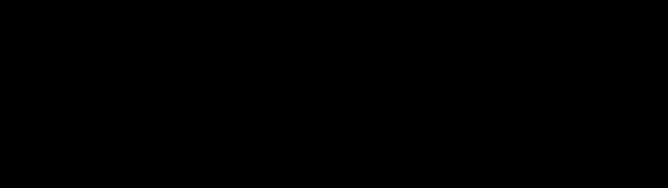

In [2]:
diagrams.plan_flow()

In [3]:
import json, tempfile
from pathlib import Path
from urbanweave.plan import Plan, replay

work = Path(tempfile.mkdtemp())
(work / "data").mkdir()
td.save_street_graph(work / "data" / "riverton.graphml")
td.districts().to_file(work / "data" / "districts.geojson", driver="GeoJSON")
crashes = td.crashes()

The plan: crashes onto street segments (within 25 m), then onto districts as crashes per
road-km. Targets are files, named relative to the plan; `crashes` is a source supplied when the plan
runs.

In [4]:
recipe = {
  "version": 1,
  "sources": {"crashes": {"kind": "vector", "columns": {"persons_injured": {"kind": "extensive", "units": "persons"}}}},
  "targets": {
    "streets": {"kind": "osm_streets", "graphml": "data/riverton.graphml"},
    "districts": {"kind": "zones", "path": "data/districts.geojson", "id_column": "district_id"}
  },
  "steps": [
    {"id": "street_crashes", "source": "crashes",
     "match": {"method": "nearest_segment", "target": "streets", "max_distance": 25},
     "aggregate": [{"method": "count", "as": "crashes", "fill_empty": 0},
                   {"method": "sum", "column": "persons_injured", "as": "injured", "fill_empty": 0}]},
    {"id": "district_density", "source": "@street_crashes",
     "match": {"method": "length_weighted", "target": "districts", "shared_boundary": "lowest_target_id"},
     "aggregate": [{"method": "density", "column": "crashes", "denominator": "overlap_length", "as": "crashes_per_road_km"},
                   {"method": "sum", "column": "injured", "as": "injured"}]}
  ]
}
(work / "crash_density.json").write_text(json.dumps(recipe, indent=2))
plan = Plan.from_json(work / "crash_density.json")
plan.validate(source_names=["crashes"])
print("valid; fingerprint", plan.fingerprint[:16])

valid; fingerprint bf34e41d17748c89


## Preflight catches mistakes before anything runs

A typo in a method, a reference to a step that comes later, and a sum of an intensive column: all
three are reported together, by step.

In [5]:
broken = json.loads(json.dumps(recipe))
broken["steps"][0]["match"]["method"] = "nearest_segmnet"
broken["steps"][1]["source"] = "@later_step"
broken["sources"]["crashes"]["columns"]["persons_injured"]["kind"] = "intensive"
try:
    Plan(broken, base_dir=work).validate(source_names=["crashes"])
except uw.PlanError as err:
    print(err)

The plan is not valid:
- step street_crashes: unknown matching method 'nearest_segmnet'.
- step street_crashes: sum does not suit intensive values ('persons_injured'); it takes extensive.
- step district_density: source @later_step is not an earlier step (forward or unknown reference).


## Run it, with a cache and a manifest

In [6]:
run = plan.run({"crashes": crashes}, cache=work / "cache", manifest_path=work / "run1.json")
run.result[["district_id", "name", "crashes_per_road_km", "injured"]].round(2)

,district_id,name,crashes_per_road_km,injured
0,NG,Northgate,9.21,45.65
1,OT,Old Town,21.82,95.1
2,EF,Eastfield,8.11,49.41
3,MD,Mill District,6.44,36.46
4,RS,Riverside,8.27,31.37


In [7]:
manifest = json.loads((work / "run1.json").read_text())
show({"sources": {k: v["fingerprint"][:16] for k, v in manifest["sources"].items()},
      "targets": {k: v["fingerprint"][:16] for k, v in manifest["targets"].items()},
      "engines": {k: manifest["engines"][k] for k in ("urbanweave", "shapely", "geopandas", "h3")}})

{
 "sources": {
  "crashes": "9b16a12efc6a4429"
 },
 "targets": {
  "districts": "9e77a799a4e62b27",
  "streets": "ffdfa6b0809c91b0"
 },
 "engines": {
  "urbanweave": "0.1.0.dev0",
  "shapely": "2.2.0",
  "geopandas": "1.2.0",
  "h3": "4.5.1"
 }
}


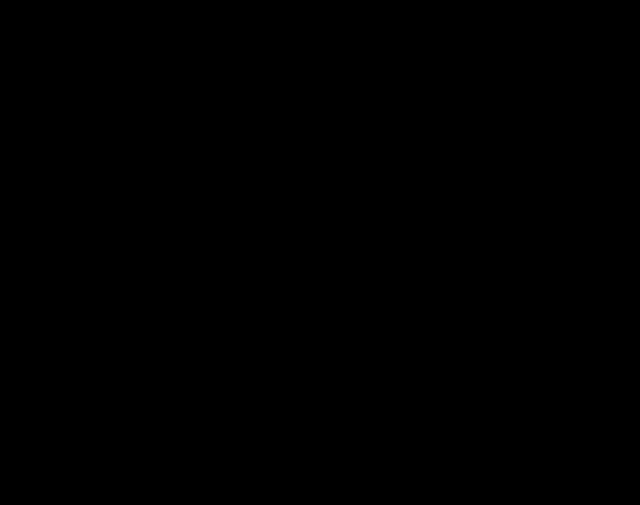

In [8]:
(Map("Crashes per road-km, from the plan")
 .fill(run.result, "crashes_per_road_km", legend="crashes per km of street", classes=5)
 .outline(run.result, label="name"))

## Replay, and what happens when an input changes

Replaying the manifest reruns the plan from the cached artifacts and gives the same numbers. If a
cached artifact is altered, replay refuses and names it; if the data file changes on disk, a new
run records the new version while the old run stays replayable from its own artifacts.

In [9]:
again = replay(work / "run1.json", cache=work / "cache")
print("same result:", again.result["crashes_per_road_km"].round(9).equals(run.result["crashes_per_road_km"].round(9)))

same result: True


In [10]:
zones_file = work / "data" / "districts.geojson"
d = td.districts()
d.loc[d["district_id"] == "OT", "geometry"] = d.loc[d["district_id"] == "OT", "geometry"].buffer(-100)  # a redrawn boundary
d.to_file(zones_file, driver="GeoJSON")
run2 = plan.run({"crashes": crashes}, cache=work / "cache", manifest_path=work / "run2.json")
m1, m2 = (json.loads((work / f).read_text()) for f in ("run1.json", "run2.json"))
print("districts artifact changed:", m1["targets"]["districts"]["fingerprint"] != m2["targets"]["districts"]["fingerprint"])
print("first run still replays:", replay(work / "run1.json", cache=work / "cache").result["crashes_per_road_km"].round(6).tolist())

districts artifact changed: True
first run still replays: [9.208928, 21.820239, 8.107958, 6.439819, 8.270214]


In [11]:
artifact = next((work / "cache" / "artifacts" / m1["targets"]["districts"]["fingerprint"]).glob("*.geojson"))
artifact.write_text(artifact.read_text().replace("Old Town", "Old Towne"))     # tamper with the pinned copy
try:
    replay(work / "run1.json", cache=work / "cache")
except uw.PlanError as err:
    print(err)

Cannot replay the run:
- target 'districts': artifact 9e77a799a4e6 (districts.geojson) changed in the cache


That completes the tour. The design document ([DESIGN.md](../DESIGN.md)) explains the package's history,
goals and the rules behind each step, and `uw.registry()` lists every operator with its parameters.